<a href="https://colab.research.google.com/github/dwikidias/UTS-Machine-Learning-kelompok-14/blob/main/DwikiDiastoro_regresi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pembelajaran Mesin - UTS ML (Task 1: Regresi)
## Estimasi Durasi Pengiriman (`P50` & `P90`)

Notebook ini disusun secara linear (*Restart & Run All*) dengan pemuatan dataset otomatis dari folder `dataset/`, dilengkapi tabel ringkasan hasil, grafik evaluasi, dan penjelasan singkat pada setiap tahap.

## 1. Setup, Reproducibility, & Pemuatan Dataset Otomatis
Sel ini mengatur *random seed* (`SEED = 42`), memastikan pustaka tersedia, menampilkan versi pustaka, dan mencari dataset `regresi_train.csv(.gz)` serta `regresi_test.csv(.gz)` secara otomatis dari folder `dataset/` (atau meng-*clone* repositori secara otomatis jika dijalankan pada *runtime* Google Colab yang masih kosong).

In [1]:
import os
import sys
import subprocess
import random
import importlib.util

# Pastikan library utama tersedia (untuk runtime baru di luar/di dalam Colab)
for pkg in ["lightgbm", "shap", "matplotlib"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import lightgbm as lgb
import shap
from IPython.display import display

# Konfigurasi Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

versions_df = pd.DataFrame([
    {"Komponen": "Python", "Versi": sys.version.split()[0]},
    {"Komponen": "NumPy", "Versi": np.__version__},
    {"Komponen": "Pandas", "Versi": pd.__version__},
    {"Komponen": "Scikit-Learn", "Versi": sklearn.__version__},
    {"Komponen": "LightGBM", "Versi": lgb.__version__},
    {"Komponen": "SHAP", "Versi": shap.__version__},
])
display(versions_df)

# Pencarian otomatis folder dataset/ (lokal, subfolder kode/, atau Colab)
REPO_URL = os.environ.get("UTS_REPO_URL", "https://github.com/dwikidias/UTS-Machine-Learning-kelompok-14.git")
REPO_DIR = "UTS-Machine-Learning-kelompok-14"

def resolve_paths():
    env_dir = os.environ.get("UTS_DATA_DIR")
    if env_dir and os.path.isdir(env_dir):
        return env_dir, "."
    candidates = [
        ("dataset", "."),
        (os.path.join("..", "dataset"), ".."),
        (os.path.join(REPO_DIR, "dataset"), REPO_DIR),
    ]
    for d_path, out_root in candidates:
        if os.path.isdir(d_path):
            return d_path, out_root
    # Jika belum ada (misalnya baru buka di Google Colab kosong), clone repo otomatis
    print(f"Folder dataset/ belum ditemukan. Mengambil repositori dari {REPO_URL} ...")
    subprocess.check_call(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR])
    return os.path.join(REPO_DIR, "dataset"), REPO_DIR

DATA_DIR, OUTPUT_ROOT = resolve_paths()
print(f"Menggunakan folder dataset : {os.path.abspath(DATA_DIR)}")
print(f"Folder output prediksi     : {os.path.abspath(OUTPUT_ROOT)}")

def load_dataset(base_name):
    gz_path = os.path.join(DATA_DIR, f"{base_name}.csv.gz")
    csv_path = os.path.join(DATA_DIR, f"{base_name}.csv")
    if os.path.exists(gz_path):
        return pd.read_csv(gz_path, compression="gzip")
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f"File '{base_name}.csv.gz' atau '{base_name}.csv' tidak ditemukan di {DATA_DIR}")

train_df = load_dataset("regresi_train")
test_df = load_dataset("regresi_test")

summary_data = pd.DataFrame([
    {"Dataset": "regresi_train", "Baris": train_df.shape[0], "Kolom": train_df.shape[1]},
    {"Dataset": "regresi_test",  "Baris": test_df.shape[0],  "Kolom": test_df.shape[1]},
])
display(summary_data)

,Komponen,Versi
0,Python,3.13.18
1,NumPy,2.4.6
2,Pandas,2.2.3
3,Scikit-Learn,1.6.1
4,LightGBM,4.6.0
5,SHAP,0.54.1


Menggunakan folder dataset : /content/UTS-Machine-Learning-kelompok-14/dataset
Folder output prediksi     : /content/UTS-Machine-Learning-kelompok-14


,Dataset,Baris,Kolom
0,regresi_train,250000,77
1,regresi_test,60000,76


## 2. Fungsi Preprocessing (*Leakage-Free*) & Penyelarasan Kategori
- `prepare_features`: menghitung statistik imputasi (`jarak_km` untuk nilai sentinel `0`/`9999`, `berat_kg` *missing*, dan *frequency encoding*) **hanya dari data latih**, lalu menerapkannya ke data validasi/uji agar bebas *data leakage*.
- `align_categories`: memetakan kategori baru yang hanya muncul di data uji (seperti `mitra_kurir = K13`) ke label `__UNKNOWN__`.


In [2]:
def prepare_features(df_in, route_medians=None, hub_medians=None, global_jarak_med=None, layanan_berat_med=None, freq_maps=None):
    d = df_in.copy()
    d['tgl_pickup'] = pd.to_datetime(d['tgl_pickup'])
    d['pickup_month'] = d['tgl_pickup'].dt.month
    d['pickup_dayofweek'] = d['tgl_pickup'].dt.dayofweek
    d['pickup_is_weekend'] = (d['pickup_dayofweek'] >= 5).astype(int)
    if 'jam_pickup' in d.columns:
        if d['jam_pickup'].dtype == 'object':
            d['jam_pickup_hour'] = pd.to_datetime(d['jam_pickup'], format='%H:%M:%S', errors='coerce').dt.hour.fillna(12)
        else:
            d['jam_pickup_hour'] = d['jam_pickup']

    # Tangani sentinel jarak_km (0 dan 9999)
    d['is_jarak_invalid'] = d['jarak_km'].isin([0, 9999]).astype(int)
    d.loc[d['jarak_km'].isin([0, 9999]), 'jarak_km'] = np.nan

    # Flag missing berat_kg
    d['is_berat_missing'] = d['berat_kg'].isna().astype(int)

    # Fit statistik imputasi hanya pada data latih
    if route_medians is None:
        route_medians = d.groupby(['kota_asal', 'kota_tujuan'])['jarak_km'].median()
        hub_medians = d.groupby(['hub_asal', 'pulau_tujuan'])['jarak_km'].median()
        global_jarak_med = d['jarak_km'].median()
        layanan_berat_med = d.groupby('layanan')['berat_kg'].median()

    route_vals = pd.Series(d.set_index(['kota_asal', 'kota_tujuan']).index.map(route_medians).to_numpy(), index=d.index)
    hub_vals = pd.Series(d.set_index(['hub_asal', 'pulau_tujuan']).index.map(hub_medians).to_numpy(), index=d.index)
    d['jarak_km'] = d['jarak_km'].fillna(route_vals).fillna(hub_vals).fillna(global_jarak_med)
    d['berat_kg'] = d['berat_kg'].fillna(d['layanan'].map(layanan_berat_med)).fillna(layanan_berat_med.median())

    high_card_cols = ['kota_tujuan', 'kota_asal', 'mitra_kurir', 'hub_asal']
    if freq_maps is None:
        freq_maps = {col: d[col].value_counts(normalize=True).to_dict() for col in high_card_cols}
    for col in high_card_cols:
        d[f'{col}_freq'] = d[col].map(freq_maps[col]).fillna(0.0)

    return d, (route_medians, hub_medians, global_jarak_med, layanan_berat_med, freq_maps)

def align_categories(tr_df, other_dfs, cat_cols):
    tr_df = tr_df.copy()
    others = [d.copy() for d in other_dfs]
    for c in cat_cols:
        known = list(dict.fromkeys(list(tr_df[c].astype(str).unique()) + ['__UNKNOWN__']))
        dtype = pd.CategoricalDtype(categories=known, ordered=False)
        tr_df[c] = tr_df[c].astype(str).astype(dtype)
        for d in others:
            s = d[c].astype(str)
            d[c] = s.where(s.isin(known), '__UNKNOWN__').astype(dtype)
    return [tr_df] + others

## 3. Data Audit & Deteksi *Leakage*
Audit memeriksa duplikat, rentang tanggal, *missing values*, anomali `jarak_km` (`0` dan `9999`), *outlier* target `durasi_jam`, fitur pasca-*pickup* (`jumlah_scan`), serta kategori baru pada data uji (`unseen categories`).


In [3]:
# 1. Ringkasan Duplikat & Rentang Tanggal
audit_basic = pd.DataFrame([
    {"Metrik": "Duplikat id_paket (train)", "Nilai": int(train_df['id_paket'].duplicated().sum())},
    {"Metrik": "Duplikat id_paket (test)",  "Nilai": int(test_df['id_paket'].duplicated().sum())},
    {"Metrik": "Rentang tgl_pickup train",  "Nilai": f"{train_df['tgl_pickup'].min()} s/d {train_df['tgl_pickup'].max()}"},
    {"Metrik": "Rentang tgl_pickup test",   "Nilai": f"{test_df['tgl_pickup'].min()} s/d {test_df['tgl_pickup'].max()}"},
    {"Metrik": "durasi_jam <= 0 (train)",   "Nilai": int((train_df['durasi_jam'] <= 0).sum())},
])
print("=== 1. AUDIT DASAR ===")
display(audit_basic)

# 2. Missing Values (> 0%)
miss_tr = (train_df.isna().mean() * 100).round(2)
miss_ts = (test_df.isna().mean() * 100).round(2)
miss_df = pd.DataFrame({'train_%': miss_tr, 'test_%': miss_ts})
print("=== 2. MISSING VALUES (%) ===")
display(miss_df[(miss_df['train_%'] > 0) | (miss_df['test_%'] > 0)])

# 3. Anomali Numerik & Outlier durasi_jam
anom_rows = []
for col in ['jarak_km', 'berat_kg', 'volume_liter', 'nilai_barang', 'jumlah_scan']:
    if col in train_df.columns:
        anom_rows.append({
            "Fitur": col,
            "Train Min": round(float(train_df[col].min()), 3),
            "Train Max": round(float(train_df[col].max()), 3),
            "Train <= 0": int((train_df[col] <= 0).sum()),
            "Test <= 0": int((test_df[col] <= 0).sum()),
        })
print("=== 3. ANOMALI NUMERIK ===")
display(pd.DataFrame(anom_rows))

outlier_rows = []
for thresh in [250, 500, 1000, 5000]:
    cnt = int((train_df['durasi_jam'] > thresh).sum())
    outlier_rows.append({"Ambang durasi_jam": f"> {thresh} jam", "Jumlah Baris": cnt, "Persentase (%)": round(cnt / len(train_df) * 100, 3)})
print("=== 4. OUTLIER durasi_jam ===")
display(pd.DataFrame(outlier_rows))

# 4. Top 10 Korelasi Absolut terhadap durasi_jam (Deteksi Leakage)
num_cols_audit = train_df.select_dtypes(include=[np.number]).columns.drop('durasi_jam')
corrs = train_df[num_cols_audit].corrwith(train_df['durasi_jam']).abs().sort_values(ascending=False).head(10).round(4)
print("=== 5. TOP 10 KORELASI TERHADAP durasi_jam ===")
display(corrs.reset_index().rename(columns={"index": "Fitur", 0: "Korelasi Absolut"}))

# 5. Audit Kategori & Unseen di Test
cat_cols_audit = train_df.select_dtypes(include=['object', 'category']).columns.drop(['id_paket', 'tgl_pickup'], errors='ignore')
cat_rows = []
for col in cat_cols_audit:
    tr_set = set(train_df[col].dropna().unique())
    ts_set = set(test_df[col].dropna().unique())
    unseen = ts_set - tr_set
    cat_rows.append({
        "Kolom": col,
        "Unik Train": len(tr_set),
        "Unik Test": len(ts_set),
        "Unseen di Test": len(unseen),
        "Porsi Baris Test (%)": round(float(test_df[col].isin(unseen).mean() * 100), 2)
    })
print("=== 6. AUDIT KATEGORI & UNSEEN ===")
display(pd.DataFrame(cat_rows))

=== 1. AUDIT DASAR ===


,Metrik,Nilai
0,Duplikat id_paket (train),0
1,Duplikat id_paket (test),0
2,Rentang tgl_pickup train,2025-01-01 s/d 2025-08-31
3,Rentang tgl_pickup test,2025-09-01 s/d 2025-10-31
4,durasi_jam <= 0 (train),0


=== 2. MISSING VALUES (%) ===


,train_%,test_%
berat_kg,5.56,5.44


=== 3. ANOMALI NUMERIK ===


,Fitur,Train Min,Train Max,Train <= 0,Test <= 0
0,jarak_km,0.00,9999.00,703,177
1,berat_kg,0.02,683.34,0,0
2,volume_liter,0.10,4596.80,0,0
3,nilai_barang,2000.00,48400000.00,0,0
4,jumlah_scan,1.00,97.00,0,0


... (2 outputs left out)

=== 5. TOP 10 KORELASI TERHADAP durasi_jam ===


,Fitur,Korelasi Absolut
0,jumlah_scan,0.1887
1,f04,0.1027
2,jarak_km,0.0963
3,f05,0.0794
4,f22,0.0742
5,f23,0.0579
6,f17,0.0404
7,antrean_hub_asal,0.0288
8,alamat_skor,0.0279
9,f09,0.0275


=== 6. AUDIT KATEGORI & UNSEEN ===


,Kolom,Unik Train,Unik Test,Unseen di Test,Porsi Baris Test (%)
0,layanan,4,4,0,0.0
1,mitra_kurir,12,13,1,3.9
2,hub_asal,6,6,0,0.0
3,kota_asal,30,30,0,0.0
4,pulau_tujuan,7,7,0,0.0
5,kota_tujuan,405,405,0,0.0


## 4. Desain Validasi (*Time-Based* vs *Random CV*) & Dampak *Leakage*
Data uji berasal dari bulan mendatang (September–Oktober 2025). Sel ini membandingkan:
1. **Time-Based Validation** (Train Jan–Jun 2025, Val Jul–Ags 2025) **dengan** fitur bocor `jumlah_scan` vs **tanpa** `jumlah_scan`.
2. **Random 5-Fold CV** tanpa `jumlah_scan` untuk menunjukkan bias optimistis jika validasi mengabaikan urutan waktu.


In [4]:
from sklearn.model_selection import KFold

def pinball_loss(y_true, y_pred, q):
    err = y_true - y_pred
    return float(np.mean(np.maximum(q * err, (q - 1) * err)))

def evaluate_predictions(y_true, p50, p90, label=""):
    l50 = pinball_loss(y_true, p50, 0.5)
    l90 = pinball_loss(y_true, p90, 0.9)
    cov90 = float(np.mean(y_true <= p90) * 100)
    return {"Skema / Model": label, "Pinball P50": round(l50, 4), "Pinball P90": round(l90, 4), "P90 Coverage (%)": round(cov90, 2)}

df_val = train_df.copy()
df_val['tgl_pickup'] = pd.to_datetime(df_val['tgl_pickup'])
cat_cols = ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
for c in cat_cols:
    df_val[c] = df_val[c].astype('category')

df_val['pickup_month'] = df_val['tgl_pickup'].dt.month
df_val['pickup_dayofweek'] = df_val['tgl_pickup'].dt.dayofweek

drop_base = ['id_paket', 'tgl_pickup', 'durasi_jam']
if 'jam_pickup' in df_val.columns and df_val['jam_pickup'].dtype == 'object':
    df_val['jam_pickup_hour'] = pd.to_datetime(df_val['jam_pickup'], format='%H:%M:%S', errors='coerce').dt.hour
    drop_base.append('jam_pickup')

features_with_leak = [c for c in df_val.columns if c not in drop_base]
features_no_leak   = [c for c in features_with_leak if c != 'jumlah_scan']

tr_mask = df_val['tgl_pickup'] < '2025-07-01'
va_mask = df_val['tgl_pickup'] >= '2025-07-01'

def fit_predict_lgb(X_tr, y_tr, X_va):
    m50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1)
    m90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1)
    m50.fit(X_tr, y_tr)
    m90.fit(X_tr, y_tr)
    return m50.predict(X_va), m90.predict(X_va)

val_results = []
p50_leak, p90_leak = fit_predict_lgb(df_val.loc[tr_mask, features_with_leak], df_val.loc[tr_mask, 'durasi_jam'], df_val.loc[va_mask, features_with_leak])
val_results.append(evaluate_predictions(df_val.loc[va_mask, 'durasi_jam'].values, p50_leak, p90_leak, "Time-Val DENGAN jumlah_scan (LEAK)"))

p50_clean, p90_clean = fit_predict_lgb(df_val.loc[tr_mask, features_no_leak], df_val.loc[tr_mask, 'durasi_jam'], df_val.loc[va_mask, features_no_leak])
val_results.append(evaluate_predictions(df_val.loc[va_mask, 'durasi_jam'].values, p50_clean, p90_clean, "Time-Val TANPA jumlah_scan (BERSIH)"))

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
l50_cv, l90_cv, cov_cv = [], [], []
for tr_i, va_i in kf.split(df_val):
    p50_f, p90_f = fit_predict_lgb(df_val.iloc[tr_i][features_no_leak], df_val.iloc[tr_i]['durasi_jam'], df_val.iloc[va_i][features_no_leak])
    l50_cv.append(pinball_loss(df_val.iloc[va_i]['durasi_jam'].values, p50_f, 0.5))
    l90_cv.append(pinball_loss(df_val.iloc[va_i]['durasi_jam'].values, p90_f, 0.9))
    cov_cv.append(np.mean(df_val.iloc[va_i]['durasi_jam'].values <= p90_f) * 100)

val_results.append({
    "Skema / Model": "Random 5-Fold CV (TANPA leak)",
    "Pinball P50": round(float(np.mean(l50_cv)), 4),
    "Pinball P90": round(float(np.mean(l90_cv)), 4),
    "P90 Coverage (%)": round(float(np.mean(cov_cv)), 2)
})
display(pd.DataFrame(val_results))

,Skema / Model,Pinball P50,Pinball P90,P90 Coverage (%)
0,Time-Val DENGAN jumlah_scan (LEAK),9.3159,9.8777,87.15
1,Time-Val TANPA jumlah_scan (BERSIH),10.8000,11.3999,86.24
2,Random 5-Fold CV (TANPA leak),9.9609,10.1438,88.85


## 5. Perbandingan Model & Kalibrasi Conformal (CQR)
Data dibagi secara kronologis menjadi **Train** (Jan–Jun 2025), **Calibration** (Jul 2025 untuk menghitung *delta* CQR), dan **Evaluation** (Ags 2025). Tiga keluarga model dibandingkan:
1. **Baseline**: Kuantil P50 dan P90 per jenis `layanan`.
2. **Ridge Regression**: Transformasi target `log1p(durasi_jam)` + residual kuantil ke-90 pada set kalibrasi.
3. **LightGBM Quantile (`alpha=0.5` & `0.9`) + CQR**: Menggeser batas atas `p90` dengan konstanta kalibrasi dari Juli 2025 agar *P90 coverage* mendekati 90%.


Delta Conformal P90 (Juli 2025): +6.9424 jam


,Skema / Model,Pinball P50,Pinball P90,P90 Coverage (%)
0,0. Baseline (Per Layanan),15.8670,15.1018,89.55
1,1. Ridge (log1p + Residual Q90),11.4468,11.6230,89.83
2,2. LightGBM (Sebelum Kalibrasi),10.7526,11.5024,85.35
3,3. LightGBM + Conformal (CQR),10.7526,11.3787,90.65


,Skema / Model,Pinball P50,Pinball P90,P90 Coverage (%)
0,0. Baseline (Per Layanan),15.8670,15.1018,89.55
1,1. Ridge (log1p + Residual Q90),11.4468,11.6230,89.83
2,2. LightGBM (Sebelum Kalibrasi),10.7526,11.5024,85.35
3,3. LightGBM + Conformal (CQR),10.7526,11.3787,90.65


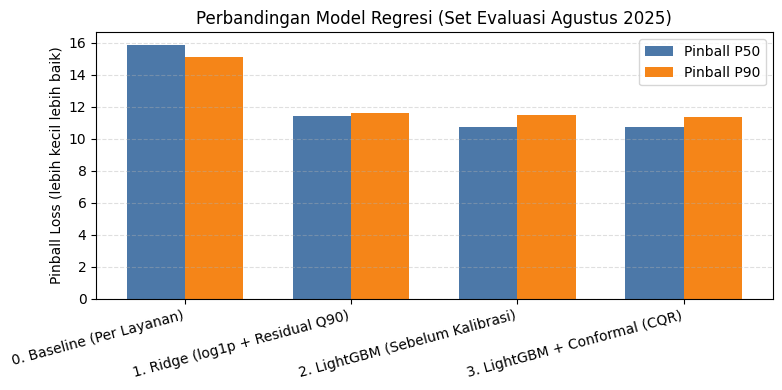

In [5]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

train_raw = train_df[train_df['tgl_pickup'] < '2025-07-01']
cal_raw   = train_df[(train_df['tgl_pickup'] >= '2025-07-01') & (train_df['tgl_pickup'] < '2025-08-01')]
eval_raw  = train_df[train_df['tgl_pickup'] >= '2025-08-01']

tr_prep, stats_pack = prepare_features(train_raw)
cal_prep, _ = prepare_features(cal_raw, *stats_pack)
ev_prep, _  = prepare_features(eval_raw, *stats_pack)

cat_cols = ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
drop_cols = ['id_paket', 'tgl_pickup', 'jam_pickup', 'durasi_jam', 'jumlah_scan']
feat_cols = [c for c in tr_prep.columns if c not in drop_cols]
num_cols = [c for c in feat_cols if c not in cat_cols]

y_tr, y_cal, y_ev = tr_prep['durasi_jam'].values, cal_prep['durasi_jam'].values, ev_prep['durasi_jam'].values
model_results = []

# 0. Baseline
base_p50_map = tr_prep.groupby('layanan', observed=False)['durasi_jam'].quantile(0.5).to_dict()
base_p90_map = tr_prep.groupby('layanan', observed=False)['durasi_jam'].quantile(0.9).to_dict()
p50_base = ev_prep['layanan'].map(base_p50_map).values
p90_base = ev_prep['layanan'].map(base_p90_map).values
model_results.append(evaluate_predictions(y_ev, p50_base, p90_base, "0. Baseline (Per Layanan)"))

# 1. Ridge
pre_linear = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), cat_cols)
])
ridge_pipe = Pipeline([('pre', pre_linear), ('model', Ridge(alpha=10.0, random_state=SEED))])
ridge_pipe.fit(tr_prep[feat_cols], np.log1p(y_tr))
log_pred_cal = ridge_pipe.predict(cal_prep[feat_cols])
q90_res_log = np.quantile(np.log1p(y_cal) - log_pred_cal, 0.90)
log_pred_ev = ridge_pipe.predict(ev_prep[feat_cols])
p50_ridge = np.expm1(log_pred_ev)
p90_ridge = np.maximum(p50_ridge, np.expm1(log_pred_ev + q90_res_log))
model_results.append(evaluate_predictions(y_ev, p50_ridge, p90_ridge, "1. Ridge (log1p + Residual Q90)"))

# 2. LightGBM Untuned & CQR
tr_prep, cal_prep, ev_prep = align_categories(tr_prep, [cal_prep, ev_prep], cat_cols)
lgb50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=SEED, verbose=-1)
lgb90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=SEED, verbose=-1)
lgb50.fit(tr_prep[feat_cols], y_tr)
lgb90.fit(tr_prep[feat_cols], y_tr)

p50_lgb_cal = lgb50.predict(cal_prep[feat_cols])
p90_lgb_cal = np.maximum(p50_lgb_cal, lgb90.predict(cal_prep[feat_cols]))
p50_lgb_ev = lgb50.predict(ev_prep[feat_cols])
p90_lgb_ev = np.maximum(p50_lgb_ev, lgb90.predict(ev_prep[feat_cols]))
model_results.append(evaluate_predictions(y_ev, p50_lgb_ev, p90_lgb_ev, "2. LightGBM (Sebelum Kalibrasi)"))

delta_90 = np.quantile(y_cal - p90_lgb_cal, 0.90)
p90_lgb_cqr = np.maximum(p50_lgb_ev, p90_lgb_ev + delta_90)
print(f"Delta Conformal P90 (Juli 2025): +{delta_90:.4f} jam")
model_results.append(evaluate_predictions(y_ev, p50_lgb_ev, p90_lgb_cqr, "3. LightGBM + Conformal (CQR)"))

display(pd.DataFrame(model_results))
comp_df = pd.DataFrame(model_results)
display(comp_df)

# Visualisasi Perbandingan Pinball Loss Antar Model
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(comp_df))
w = 0.35
ax.bar(x - w/2, comp_df["Pinball P50"], width=w, label="Pinball P50", color="#4C78A8")
ax.bar(x + w/2, comp_df["Pinball P90"], width=w, label="Pinball P90", color="#F58518")
ax.set_xticks(x)
ax.set_xticklabels(comp_df["Skema / Model"], rotation=15, ha="right")
ax.set_ylabel("Pinball Loss (lebih kecil lebih baik)")
ax.set_title("Perbandingan Model Regresi (Set Evaluasi Agustus 2025)")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 6. Hyperparameter Tuning LightGBM (di dalam Time-Based Validation)
Tuning dilakukan pada `train_raw` (Jan–Jun 2025) dan dievaluasi pada `cal_raw` (Jul 2025) untuk memilih konfigurasi terbaik masing-masing untuk `P50` dan `P90`.


In [6]:
param_candidates = [
    {'num_leaves': 31,  'learning_rate': 0.05, 'min_child_samples': 50,  'n_estimators': 400},
    {'num_leaves': 63,  'learning_rate': 0.05, 'min_child_samples': 50,  'n_estimators': 500},
    {'num_leaves': 63,  'learning_rate': 0.03, 'min_child_samples': 100, 'n_estimators': 700},
    {'num_leaves': 127, 'learning_rate': 0.03, 'min_child_samples': 100, 'n_estimators': 700},
]

tuning_logs = []
for idx, params in enumerate(param_candidates):
    m50_t = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=SEED, verbose=-1, **params)
    m90_t = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=SEED, verbose=-1, **params)
    m50_t.fit(tr_prep[feat_cols], y_tr)
    m90_t.fit(tr_prep[feat_cols], y_tr)

    p50_c = m50_t.predict(cal_prep[feat_cols])
    p90_c = np.maximum(p50_c, m90_t.predict(cal_prep[feat_cols]))
    tuning_logs.append({
        'id': idx,
        **params,
        'val_pinball_p50': round(pinball_loss(y_cal, p50_c, 0.5), 4),
        'val_pinball_p90': round(pinball_loss(y_cal, p90_c, 0.9), 4),
        'val_cov90_%': round(float(np.mean(y_cal <= p90_c) * 100), 2)
    })

tuning_df = pd.DataFrame(tuning_logs).sort_values('val_pinball_p50')
display(tuning_df)

,id,num_leaves,learning_rate,min_child_samples,n_estimators,val_pinball_p50,val_pinball_p90,val_cov90_%
3,3,127,0.03,100,700,10.7400,11.3968,84.50
1,1,63,0.05,50,500,10.7467,11.3761,84.67
2,2,63,0.03,100,700,10.7503,11.3478,84.99
0,0,31,0.05,50,400,10.7556,11.3065,85.72


## 7. Evaluasi Model Final & Generasi `prediksi_regresi.csv`
Model *tuned* (`id=3` untuk P50 dan `id=0` untuk P90) dievaluasi pada Agustus 2025, lalu dilatih ulang menggunakan seluruh `train_df` untuk menghasilkan `prediksi_regresi.csv` (`60.000` baris, syarat `p90 >= p50`).


Delta Conformal P90 (Juli 2025): +5.8094 jam


,Skema / Model,Pinball P50,Pinball P90,P90 Coverage (%)
0,Tuned LightGBM + CQR (Ags 2025),10.739,11.3658,90.54


prediksi_regresi.csv berhasil disimpan di UTS-Machine-Learning-kelompok-14/prediksi_regresi.csv | Shape: (60000, 3)


,id_paket,p50,p90
0,P83639399,59.1987,79.3797
1,P26553951,104.9910,138.2390
2,P32537117,58.9272,88.8568
3,P28750760,65.4104,89.3407
4,P96580009,53.2567,73.8858
5,P48017366,179.4122,234.4591
6,P43165236,66.6199,89.0638
7,P66505512,50.7836,72.5980
8,P46572172,92.0974,134.9090
9,P88334628,66.5703,92.6892


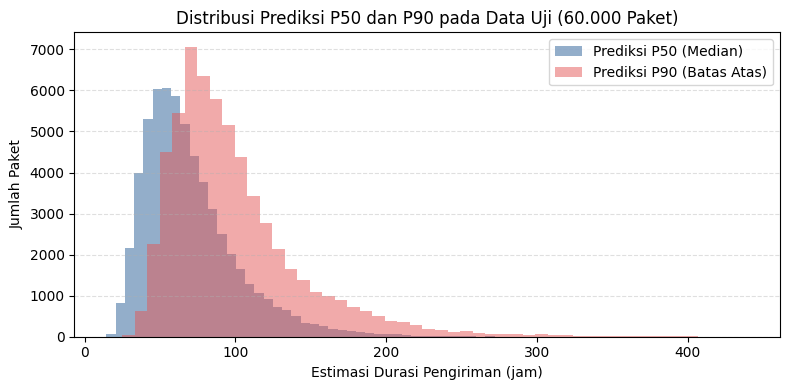

In [7]:
params_p50 = {'num_leaves': 127, 'learning_rate': 0.03, 'min_child_samples': 100, 'n_estimators': 700}
params_p90 = {'num_leaves': 31,  'learning_rate': 0.05, 'min_child_samples': 50,  'n_estimators': 400}

m50_tuned = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=SEED, verbose=-1, **params_p50)
m90_tuned = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=SEED, verbose=-1, **params_p90)
m50_tuned.fit(tr_prep[feat_cols], y_tr)
m90_tuned.fit(tr_prep[feat_cols], y_tr)

p50_cal = m50_tuned.predict(cal_prep[feat_cols])
p90_cal = np.maximum(p50_cal, m90_tuned.predict(cal_prep[feat_cols]))
delta_90_final = np.quantile(y_cal - p90_cal, 0.90)

p50_ev_final = m50_tuned.predict(ev_prep[feat_cols])
p90_ev_final = np.maximum(p50_ev_final, m90_tuned.predict(ev_prep[feat_cols]) + delta_90_final)

print(f"Delta Conformal P90 (Juli 2025): +{delta_90_final:.4f} jam")
display(pd.DataFrame([evaluate_predictions(y_ev, p50_ev_final, p90_ev_final, "Tuned LightGBM + CQR (Ags 2025)")]))

# Retrain pada seluruh train_df -> prediksi test_df
full_tr_prep, full_stats_pack = prepare_features(train_df)
full_ts_prep, _ = prepare_features(test_df, *full_stats_pack)
full_tr_prep, full_ts_prep = align_categories(full_tr_prep, [full_ts_prep], cat_cols)

lgb50_final = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=SEED, verbose=-1, **params_p50)
lgb90_final = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=SEED, verbose=-1, **params_p90)
lgb50_final.fit(full_tr_prep[feat_cols], full_tr_prep['durasi_jam'].values)
lgb90_final.fit(full_tr_prep[feat_cols], full_tr_prep['durasi_jam'].values)

p50_test = lgb50_final.predict(full_ts_prep[feat_cols])
p90_test = np.maximum(p50_test, lgb90_final.predict(full_ts_prep[feat_cols]) + delta_90_final)

sub_regresi = pd.DataFrame({
    'id_paket': test_df['id_paket'],
    'p50': np.round(p50_test, 4),
    'p90': np.round(p90_test, 4)
})
assert list(sub_regresi.columns) == ['id_paket', 'p50', 'p90']
assert len(sub_regresi) == len(test_df)
assert not sub_regresi.isna().any().any()
assert (sub_regresi['p90'] >= sub_regresi['p50']).all()

out_csv = os.path.join(OUTPUT_ROOT, 'prediksi_regresi.csv')
sub_regresi.to_csv(out_csv, index=False)
print("prediksi_regresi.csv berhasil disimpan di", out_csv, "| Shape:", sub_regresi.shape)
display(sub_regresi.head(10))

# Visualisasi Distribusi Prediksi P50 vs P90 pada Data Uji
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sub_regresi['p50'], bins=50, alpha=0.6, label='Prediksi P50 (Median)', color='#4C78A8')
ax.hist(sub_regresi['p90'], bins=50, alpha=0.5, label='Prediksi P90 (Batas Atas)', color='#E45756')
ax.set_xlabel('Estimasi Durasi Pengiriman (jam)')
ax.set_ylabel('Jumlah Paket')
ax.set_title('Distribusi Prediksi P50 dan P90 pada Data Uji (60.000 Paket)')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 8. Error Breakdown & Interpretabilitas (SHAP)
Menampilkan tabel error per `layanan`, `pulau_tujuan`, dan `mitra_kurir` pada set evaluasi Agustus 2025, serta 15 fitur paling berpengaruh berdasarkan *mean absolute SHAP value*.


=== ERROR BREAKDOWN BY LAYANAN ===


,layanan,count,pinball_p50,pinball_p90,coverage_p90_%
3,hemat,11349,14.1634,14.8984,90.22
2,kargo,3414,11.3363,11.1175,89.31
1,reguler,14335,9.6947,10.6750,90.73
0,ekspres,5070,5.6241,5.5785,91.54


=== ERROR BREAKDOWN BY PULAU_TUJUAN ===


,pulau_tujuan,count,pinball_p50,pinball_p90,coverage_p90_%
1,Sulawesi,2181,26.5796,34.6598,89.09
4,Kalimantan,1981,23.9946,29.6664,88.34
5,Maluku,679,23.4727,25.8235,92.05
6,Papua,603,21.1856,11.6408,88.56
3,Bali-Nusa Tenggara,1257,12.2903,12.4192,90.77
2,Sumatera,4550,10.9091,10.8204,90.29
0,Jawa,22917,7.3146,7.1819,90.91


=== ERROR BREAKDOWN BY MITRA_KURIR ===


,mitra_kurir,count,pinball_p50,pinball_p90,coverage_p90_%
0,K07,2677,18.5580,18.4842,68.51
11,K06,2719,16.3782,21.6899,92.09
4,K02,4139,13.1163,15.2100,91.28
10,K09,2064,10.0553,11.1797,91.72
2,K03,3806,9.6590,9.5994,92.12
5,K01,4904,9.5936,10.4727,92.64
9,K10,1982,9.5609,9.4692,91.93
1,K05,3040,8.7666,8.5202,92.63
6,K04,3392,8.2219,7.8038,93.07
3,K12,1414,7.8899,6.5648,91.65


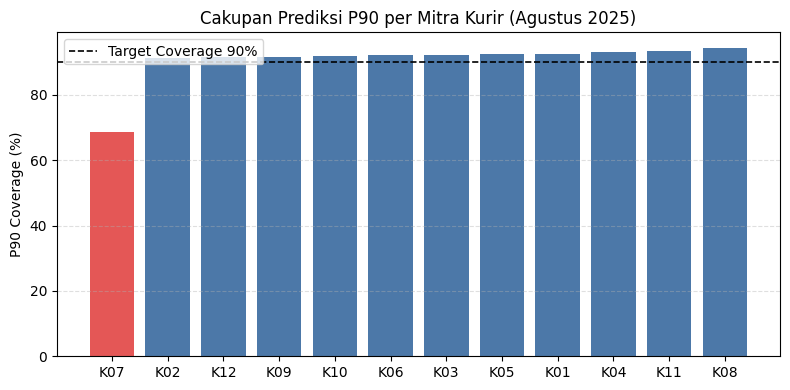

=== TOP 15 FITUR PALING BERPENGARUH (SHAP P50) ===


,fitur,mean_abs_shap
0,layanan,11.8485
6,jarak_km,10.9013
5,kota_tujuan,5.0829
25,f04,3.7053
38,f17,3.5537
1,mitra_kurir,2.9621
18,antrean_hub_asal,2.5428
12,cod,1.8569
4,pulau_tujuan,1.7373
81,hub_asal_freq,1.3903


/tmp/ipykernel_16634/1844869941.py:47: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, shap_sample, max_display=15, show=True)


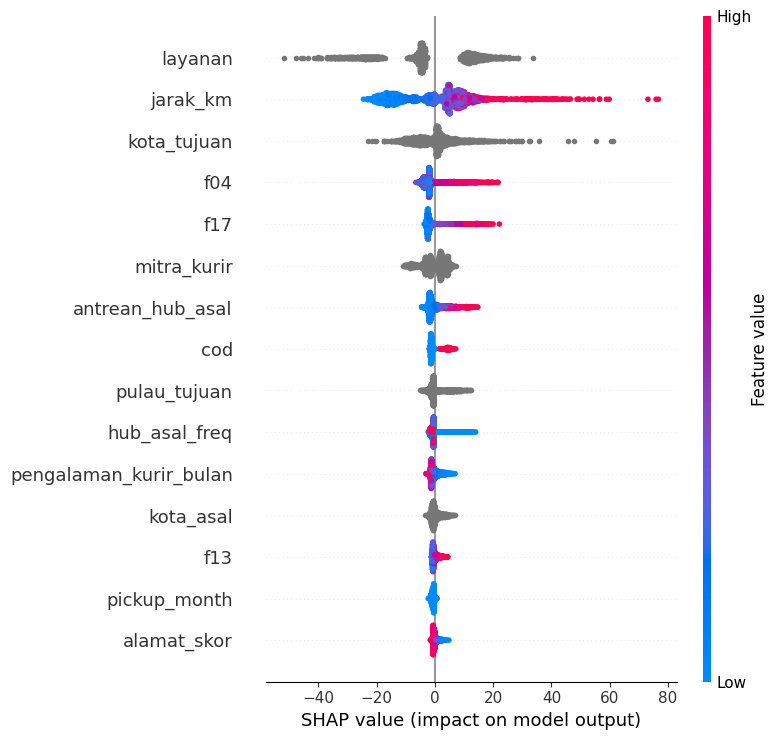

In [8]:
eval_res = ev_prep[['layanan', 'pulau_tujuan', 'mitra_kurir']].copy()
eval_res['y_true'] = y_ev
eval_res['p50'] = p50_ev_final
eval_res['p90'] = p90_ev_final

def breakdown_metrics(df_grp, col):
    rows = []
    for k, g in df_grp.groupby(col, observed=True):
        rows.append({
            col: k,
            'count': len(g),
            'pinball_p50': round(pinball_loss(g['y_true'].values, g['p50'].values, 0.5), 4),
            'pinball_p90': round(pinball_loss(g['y_true'].values, g['p90'].values, 0.9), 4),
            'coverage_p90_%': round(float(np.mean(g['y_true'].values <= g['p90'].values) * 100), 2)
        })
    return pd.DataFrame(rows).sort_values('pinball_p50', ascending=False)

for seg_col in ['layanan', 'pulau_tujuan', 'mitra_kurir']:
    print(f"=== ERROR BREAKDOWN BY {seg_col.upper()} ===")
    display(breakdown_metrics(eval_res, seg_col))

# Interpretabilitas Model dengan SHAP
shap_sample = ev_prep[feat_cols].sample(n=min(2000, len(ev_prep)), random_state=SEED)
explainer = shap.TreeExplainer(m50_tuned)
shap_values = explainer.shap_values(shap_sample)

mean_abs_shap = pd.DataFrame({
    'fitur': feat_cols,
    'mean_abs_shap': np.round(np.abs(shap_values).mean(axis=0), 4)
}).sort_values('mean_abs_shap', ascending=False).head(15)

# Visualisasi Coverage P90 per Mitra Kurir (menyorot K07)
kurir_df = breakdown_metrics(eval_res, 'mitra_kurir').sort_values('coverage_p90_%')
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#E45756' if v < 85 else '#4C78A8' for v in kurir_df['coverage_p90_%']]
ax.bar(kurir_df['mitra_kurir'].astype(str), kurir_df['coverage_p90_%'], color=colors)
ax.axhline(90, color='black', linestyle='--', linewidth=1.2, label='Target Coverage 90%')
ax.set_ylabel('P90 Coverage (%)')
ax.set_title('Cakupan Prediksi P90 per Mitra Kurir (Agustus 2025)')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print("=== TOP 15 FITUR PALING BERPENGARUH (SHAP P50) ===")
display(mean_abs_shap)
shap.summary_plot(shap_values, shap_sample, max_display=15, show=True)

## 9. Skrip Reproduktibilitas Mandiri (`run_task1.py`) & Simpan Hasil
Sel `%%writefile run_task1.py` menulis skrip mandiri yang otomatis mencari folder `dataset/` (sama seperti notebook), lalu mengeksekusi ulang evaluasi dan menyimpan `prediksi_regresi.csv`.

In [9]:
%%writefile run_task1.py
# -*- coding: utf-8 -*-
import os
import sys
import random
import numpy as np
import pandas as pd
import sklearn
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print("=== LIBRARY VERSIONS ===")
print(f"Python      : {sys.version.split()[0]}")
print(f"NumPy       : {np.__version__}")
print(f"Pandas      : {pd.__version__}")
print(f"Scikit-Learn: {sklearn.__version__}")
print(f"LightGBM    : {lgb.__version__}")

DATA_DIR = os.environ.get('UTS_DATA_DIR')
OUTPUT_ROOT = '.'
if not DATA_DIR:
    for d_cand, out_cand in [('dataset', '.'), (os.path.join('..', 'dataset'), '..'), (os.path.join('UTS-Machine-Learning-kelompok-14', 'dataset'), 'UTS-Machine-Learning-kelompok-14')]:
        if os.path.isdir(d_cand):
            DATA_DIR, OUTPUT_ROOT = d_cand, out_cand
            break
if not DATA_DIR:
    raise FileNotFoundError("Folder 'dataset/' tidak ditemukan. Jalankan dari root repo atau folder kode/.")

def load_dataset(base_name):
    gz_path = os.path.join(DATA_DIR, f'{base_name}.csv.gz')
    csv_path = os.path.join(DATA_DIR, f'{base_name}.csv')
    if os.path.exists(gz_path):
        return pd.read_csv(gz_path)
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'File {base_name}.csv(.gz) tidak ditemukan di {DATA_DIR}')

print("\nMemuat data dari:", DATA_DIR)
train_df = load_dataset('regresi_train')
test_df = load_dataset('regresi_test')

def prepare_features(df_in, route_medians=None, hub_medians=None, global_jarak_med=None, layanan_berat_med=None, freq_maps=None):
    d = df_in.copy()
    d['tgl_pickup'] = pd.to_datetime(d['tgl_pickup'])
    d['pickup_month'] = d['tgl_pickup'].dt.month
    d['pickup_dayofweek'] = d['tgl_pickup'].dt.dayofweek
    d['pickup_is_weekend'] = (d['pickup_dayofweek'] >= 5).astype(int)
    if 'jam_pickup' in d.columns:
        if d['jam_pickup'].dtype == 'object':
            d['jam_pickup_hour'] = pd.to_datetime(d['jam_pickup'], format='%H:%M:%S', errors='coerce').dt.hour.fillna(12)
        else:
            d['jam_pickup_hour'] = d['jam_pickup']
    d['is_jarak_invalid'] = d['jarak_km'].isin([0, 9999]).astype(int)
    d.loc[d['jarak_km'].isin([0, 9999]), 'jarak_km'] = np.nan
    d['is_berat_missing'] = d['berat_kg'].isna().astype(int)
    if route_medians is None:
        route_medians = d.groupby(['kota_asal', 'kota_tujuan'])['jarak_km'].median()
        hub_medians = d.groupby(['hub_asal', 'pulau_tujuan'])['jarak_km'].median()
        global_jarak_med = d['jarak_km'].median()
        layanan_berat_med = d.groupby('layanan')['berat_kg'].median()
    route_vals = pd.Series(d.set_index(['kota_asal', 'kota_tujuan']).index.map(route_medians).to_numpy(), index=d.index)
    hub_vals = pd.Series(d.set_index(['hub_asal', 'pulau_tujuan']).index.map(hub_medians).to_numpy(), index=d.index)
    d['jarak_km'] = d['jarak_km'].fillna(route_vals).fillna(hub_vals).fillna(global_jarak_med)
    d['berat_kg'] = d['berat_kg'].fillna(d['layanan'].map(layanan_berat_med)).fillna(layanan_berat_med.median())
    high_card_cols = ['kota_tujuan', 'kota_asal', 'mitra_kurir', 'hub_asal']
    if freq_maps is None:
        freq_maps = {col: d[col].value_counts(normalize=True).to_dict() for col in high_card_cols}
    for col in high_card_cols:
        d[f'{col}_freq'] = d[col].map(freq_maps[col]).fillna(0.0)
    return d, (route_medians, hub_medians, global_jarak_med, layanan_berat_med, freq_maps)

def align_categories(tr_df, other_dfs, cat_cols):
    tr_df = tr_df.copy()
    others = [d.copy() for d in other_dfs]
    for c in cat_cols:
        known = list(dict.fromkeys(list(tr_df[c].astype(str).unique()) + ['__UNKNOWN__']))
        dtype = pd.CategoricalDtype(categories=known, ordered=False)
        tr_df[c] = tr_df[c].astype(str).astype(dtype)
        for d in others:
            s = d[c].astype(str)
            d[c] = s.where(s.isin(known), '__UNKNOWN__').astype(dtype)
    return [tr_df] + others

def pinball_loss(y_true, y_pred, q):
    err = y_true - y_pred
    return np.mean(np.maximum(q * err, (q - 1) * err))

def evaluate_predictions(y_true, p50, p90, label=""):
    l50 = pinball_loss(y_true, p50, 0.5)
    l90 = pinball_loss(y_true, p90, 0.9)
    cov90 = np.mean(y_true <= p90) * 100
    print(f"[{label:32s}] Pinball P50={l50:.4f} | Pinball P90={l90:.4f} | P90 Coverage={cov90:.2f}%")
    return l50, l90, cov90

cat_cols = ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
drop_cols = ['id_paket', 'tgl_pickup', 'jam_pickup', 'durasi_jam', 'jumlah_scan']

train_raw = train_df[train_df['tgl_pickup'] < '2025-07-01']
cal_raw   = train_df[(train_df['tgl_pickup'] >= '2025-07-01') & (train_df['tgl_pickup'] < '2025-08-01')]
eval_raw  = train_df[train_df['tgl_pickup'] >= '2025-08-01']

tr_prep, stats_pack = prepare_features(train_raw)
cal_prep, _ = prepare_features(cal_raw, *stats_pack)
ev_prep, _  = prepare_features(eval_raw, *stats_pack)
tr_prep, cal_prep, ev_prep = align_categories(tr_prep, [cal_prep, ev_prep], cat_cols)

feat_cols = [c for c in tr_prep.columns if c not in drop_cols]
num_cols = [c for c in feat_cols if c not in cat_cols]
y_tr, y_cal, y_ev = tr_prep['durasi_jam'].values, cal_prep['durasi_jam'].values, ev_prep['durasi_jam'].values

print("\n=== REPRODUCE ALL REPORT METRICS (Agustus 2025) ===")
base_p50_map = tr_prep.groupby('layanan', observed=False)['durasi_jam'].quantile(0.5).to_dict()
base_p90_map = tr_prep.groupby('layanan', observed=False)['durasi_jam'].quantile(0.9).to_dict()
evaluate_predictions(y_ev, ev_prep['layanan'].map(base_p50_map).values, ev_prep['layanan'].map(base_p90_map).values, "0. Baseline (Per Layanan)")

pre_linear = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), cat_cols)
])
ridge_pipe = Pipeline([('pre', pre_linear), ('model', Ridge(alpha=10.0, random_state=SEED))])
ridge_pipe.fit(tr_prep[feat_cols], np.log1p(y_tr))
q90_res_log = np.quantile(np.log1p(y_cal) - ridge_pipe.predict(cal_prep[feat_cols]), 0.90)
log_pred_ev = ridge_pipe.predict(ev_prep[feat_cols])
p50_ridge = np.expm1(log_pred_ev)
p90_ridge = np.maximum(p50_ridge, np.expm1(log_pred_ev + q90_res_log))
evaluate_predictions(y_ev, p50_ridge, p90_ridge, "1. Ridge (log1p + Residual Q90)")

lgb50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=SEED, verbose=-1)
lgb90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=500, learning_rate=0.05, num_leaves=63, random_state=SEED, verbose=-1)
lgb50.fit(tr_prep[feat_cols], y_tr)
lgb90.fit(tr_prep[feat_cols], y_tr)
p50_lgb_cal = lgb50.predict(cal_prep[feat_cols])
p90_lgb_cal = np.maximum(p50_lgb_cal, lgb90.predict(cal_prep[feat_cols]))
p50_lgb_ev = lgb50.predict(ev_prep[feat_cols])
p90_lgb_ev = np.maximum(p50_lgb_ev, lgb90.predict(ev_prep[feat_cols]))
delta_90 = np.quantile(y_cal - p90_lgb_cal, 0.90)
evaluate_predictions(y_ev, p50_lgb_ev, np.maximum(p50_lgb_ev, p90_lgb_ev + delta_90), "2. LightGBM Untuned + CQR")

params_p50 = {'num_leaves': 127, 'learning_rate': 0.03, 'min_child_samples': 100, 'n_estimators': 700}
params_p90 = {'num_leaves': 31,  'learning_rate': 0.05, 'min_child_samples': 50,  'n_estimators': 400}
m50_tuned = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=SEED, verbose=-1, **params_p50)
m90_tuned = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=SEED, verbose=-1, **params_p90)
m50_tuned.fit(tr_prep[feat_cols], y_tr)
m90_tuned.fit(tr_prep[feat_cols], y_tr)
p50_cal = m50_tuned.predict(cal_prep[feat_cols])
p90_cal = np.maximum(p50_cal, m90_tuned.predict(cal_prep[feat_cols]))
delta_90_final = np.quantile(y_cal - p90_cal, 0.90)
p50_ev_final = m50_tuned.predict(ev_prep[feat_cols])
p90_ev_final = np.maximum(p50_ev_final, m90_tuned.predict(ev_prep[feat_cols]) + delta_90_final)
evaluate_predictions(y_ev, p50_ev_final, p90_ev_final, "3. Tuned LightGBM + CQR (Final)")

full_tr_prep, full_stats_pack = prepare_features(train_df)
full_ts_prep, _ = prepare_features(test_df, *full_stats_pack)
full_tr_prep, full_ts_prep = align_categories(full_tr_prep, [full_ts_prep], cat_cols)

lgb50_final = lgb.LGBMRegressor(objective='quantile', alpha=0.5, random_state=SEED, verbose=-1, **params_p50)
lgb90_final = lgb.LGBMRegressor(objective='quantile', alpha=0.9, random_state=SEED, verbose=-1, **params_p90)
lgb50_final.fit(full_tr_prep[feat_cols], full_tr_prep['durasi_jam'].values)
lgb90_final.fit(full_tr_prep[feat_cols], full_tr_prep['durasi_jam'].values)

p50_test = lgb50_final.predict(full_ts_prep[feat_cols])
p90_test = np.maximum(p50_test, lgb90_final.predict(full_ts_prep[feat_cols]) + delta_90_final)

sub_regresi = pd.DataFrame({
    'id_paket': test_df['id_paket'],
    'p50': np.round(p50_test, 4),
    'p90': np.round(p90_test, 4)
})
assert list(sub_regresi.columns) == ['id_paket', 'p50', 'p90']
assert len(sub_regresi) == len(test_df)
assert not sub_regresi.isna().any().any()
assert (sub_regresi['p90'] >= sub_regresi['p50']).all()

out_csv = os.path.join(OUTPUT_ROOT, 'prediksi_regresi.csv')
sub_regresi.to_csv(out_csv, index=False)
print("prediksi_regresi.csv berhasil disimpan di", out_csv, "| Shape:", sub_regresi.shape)

Overwriting run_task1.py


In [10]:
import sys, os
out_path = os.path.join(OUTPUT_ROOT, 'prediksi_regresi.csv')
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download(out_path)
else:
    print(f"File prediksi tersimpan di: {os.path.abspath(out_path)}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>